# 04 — Field polys to res-13 H3 cells

The field polys are the USDA NASS Crop Sequence Boundaries (CSB): one poly per field-sized area, with the crop grown in it each season (the `CDL` columns).
The notebook keeps the corn polys, fills each with res-13 H3 cells, and stores every cell's distance to the poly edge and to the centroid.
The fill (`h3_polyfillash3`) keeps the cells whose centre is inside the poly; `h3_coverash3` (every overlapping cell) and `h3_tessellateaswkb` (cells with clipped chips) are alternatives.
The setback is applied later, so a new setback needs no new fill.

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: JVM level unavailable: Spark Connect session (Serverless); using the Python level (48 functions)
geobrix: SQL expression level unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using the Python level


... EARTHDATA_TOKEN loaded from geospatial_docs.vapor_eyes.earthdata_token


True

DataFrame[]

H3PX_DIR = /Volumes/geospatial_docs/h3_pixels_crop_yield/data/h3-pixels-crop-yield


... view helpers: show_cells, show_tile (gated by INTERACTIVE_PLOTS)


## Corn field polys for each season

The demo rule: the corn polys in the two counties, nearest the Story County centre first, the first `DEMO_FIELDS`.
CSB has no season column; each season reads its own `CDL` column, and code 1 is corn.

In [0]:
csb.read(spark, CSB_DIR, "19").createOrReplaceTempView("csb_iowa")
spark.createDataFrame([(s,) for s in SEASONS], "season int").createOrReplaceTempView("seasons")
cdl = "CASE s.season " + " ".join(f"WHEN {y} THEN CAST(c.CDL{y} AS INT)" for y in range(2018, 2026)) + " END"
counties = ", ".join(f"'{c}'" for c in DEMO_COUNTIES)
limit = "" if FULL_AOI else f"WHERE rn <= {DEMO_FIELDS}"
county_filter = "" if FULL_AOI else f"AND concat(c.STATEFIPS, c.CNTYFIPS) IN ({counties})"
lon0, lat0 = STORY_CENTROID
polys = spark.sql(f"""
  WITH corn AS (
    SELECT CAST(c.CSBID AS STRING) AS field_id, concat(c.STATEFIPS, c.CNTYFIPS) AS county_fips, s.season,
           {cdl} AS cdl_code, st_setsrid(st_geomfromwkb(c.geom), 5070) AS poly_5070
    FROM csb_iowa c CROSS JOIN seasons s WHERE {cdl} = 1 {county_filter}),
  ranked AS (
    SELECT *, st_centroid(poly_5070) AS c_5070,
           row_number() OVER (PARTITION BY season ORDER BY
             st_distance(st_centroid(poly_5070), st_transform(st_geomfromwkt('POINT ({lon0} {lat0})', 4326), 5070)),
             field_id) AS rn
    FROM corn)
  SELECT field_id, county_fips, season, cdl_code, st_area(poly_5070) AS area_m2,
         st_transform(poly_5070, 4326) AS field_poly, st_transform(c_5070, 4326) AS field_centroid,
         st_contains(poly_5070, c_5070) AS centroid_in_poly
  FROM ranked {limit}""")
field_polys = _persist(polys, "field_polys", cluster_by=["field_id"])
display(spark.sql("SELECT season, county_fips, count(*) AS fields, round(sum(area_m2) / 4046.86) AS acres, "
                  "sum(CASE WHEN centroid_in_poly THEN 0 ELSE 1 END) AS centroid_outside FROM field_polys GROUP BY 1, 2"))

... wrote table field_polys (3,500 rows)


season,county_fips,fields,acres,centroid_outside
2023,19169,2755,155094.0,93
2023,19015,745,43092.0,20


## Fill at res 13 and measure two distances

`edge_dist_m` is the distance from each cell centre to the poly boundary (every ring, holes included), and `centroid_dist_m` the distance to the centroid.
Both are in metres, measured in EPSG:5070.

In [0]:
cells = spark.sql(f"""
  WITH f AS (SELECT field_id, county_fips, season, field_poly,
                    st_boundary(st_transform(field_poly, 5070)) AS edge_5070,
                    st_centroid(st_transform(field_poly, 5070)) AS ctr_5070
             FROM field_polys),
  c AS (SELECT f.*, cell FROM f LATERAL VIEW explode(h3_polyfillash3(st_asbinary(f.field_poly), {FIELD_H3_RES})) e AS cell),
  p AS (SELECT c.*, st_transform(st_setsrid(st_geomfromwkb(h3_centeraswkb(cell)), 4326), 5070) AS cell_5070 FROM c)
  SELECT field_id, county_fips, season, {FIELD_H3_RES} AS field_h3_res, cell AS field_h3_cellid,
         st_distance(cell_5070, edge_5070) AS edge_dist_m, st_distance(cell_5070, ctr_5070) AS centroid_dist_m
  FROM p""").repartition(FANOUT, "field_id")
h3_field_cells = _persist(cells, "h3_field_cells", cluster_by=["field_id", "field_h3_cellid"])

... wrote table h3_field_cells (18,557,719 rows)


## Checks

The fill area should match the poly area, no poly should be empty, and the setback share is the share of cells at least `SETBACK_M` from the edge.
On Story County's 2024 corn polys, the fill area / poly area was 0.99998 at the median, 0.99811 at p10 and 1.00175 at p90, and no poly got zero cells.
The line printed below is the same ratio for the demo season.

In [0]:
chk = spark.sql(f"""
  WITH n AS (SELECT field_id, season, count(*) AS n, sum(CASE WHEN edge_dist_m >= {SETBACK_M} THEN 1 ELSE 0 END) AS kept
             FROM h3_field_cells GROUP BY 1, 2),
  a AS (SELECT p.field_id, p.season, p.area_m2, coalesce(n.n, 0) AS n, coalesce(n.kept, 0) AS kept,
               st_area(st_transform(st_setsrid(st_geomfromwkb(h3_boundaryaswkb(
                 h3_pointash3(st_astext(p.field_centroid), {FIELD_H3_RES}))), 4326), 5070)) AS cell_m2
        FROM field_polys p LEFT JOIN n USING (field_id, season))
  SELECT count(*) AS fields, sum(CASE WHEN n = 0 THEN 1 ELSE 0 END) AS empty,
         sum(n * cell_m2) / sum(area_m2) AS fill_ratio_total,
         percentile_approx(n * cell_m2 / area_m2, array(0.1, 0.5, 0.9), 100000) AS fill_ratio_p10_p50_p90,
         sum(kept) / sum(n) AS kept_share, sum(CASE WHEN kept = 0 THEN 1 ELSE 0 END) AS vanish_at_setback
  FROM a""").first()
print(chk)
assert chk["empty"] == 0
lo, mid, hi = chk["fill_ratio_p10_p50_p90"]
print(f"fill area / poly area: total {chk['fill_ratio_total']:.4f}; per field p10 {lo:.3f}, median {mid:.3f}, p90 {hi:.3f}")
assert 0.995 <= chk["fill_ratio_total"] <= 1.002, "the res-13 fill area does not match the poly area"
assert 0.80 <= chk["kept_share"] <= 0.97

Row(fields=3500, empty=0, fill_ratio_total=1.000004821885589, fill_ratio_p10_p50_p90=[0.9981721004521197, 0.9999880026214532, 1.0020902935831169], kept_share=0.9087885747165371, vanish_at_setback=3)
fill area / poly area: total 1.0000; per field p10 0.998, median 1.000, p90 1.002


A poly with a hole and a two-part poly.
The hole stays empty, cells beside the hole are set back too, and both parts are filled.

In [0]:
hole = spark.sql(f"""
  WITH g AS (SELECT st_geomfromwkt('POLYGON ((-93.500 42.000, -93.494 42.000, -93.494 42.004, -93.500 42.004, -93.500 42.000),
                                    (-93.498 42.001, -93.496 42.001, -93.496 42.003, -93.498 42.003, -93.498 42.001))', 4326) AS poly,
                    st_transform(st_geomfromwkt('POLYGON ((-93.498 42.001, -93.496 42.001, -93.496 42.003, -93.498 42.003, -93.498 42.001))', 4326), 5070) AS hole_5070),
  c AS (SELECT g.*, st_transform(st_setsrid(st_geomfromwkb(h3_centeraswkb(cell)), 4326), 5070) AS ctr
        FROM g LATERAL VIEW explode(h3_polyfillash3(st_asbinary(g.poly), {FIELD_H3_RES})) e AS cell)
  SELECT count(*) AS n, sum(CASE WHEN st_contains(hole_5070, ctr) THEN 1 ELSE 0 END) AS in_hole,
         sum(CASE WHEN st_distance(ctr, st_boundary(st_transform(poly, 5070))) > st_distance(ctr, st_boundary(hole_5070)) + 1e-6
             THEN 1 ELSE 0 END) AS hole_ignored,
         sum(CASE WHEN st_distance(ctr, st_boundary(hole_5070)) < {SETBACK_M} THEN 1 ELSE 0 END) AS beside_hole
  FROM c""").first()
print(hole)
assert hole["n"] > 0 and hole["in_hole"] == 0 and hole["hole_ignored"] == 0 and hole["beside_hole"] > 0
parts = spark.sql(f"""
  SELECT count(DISTINCT CASE WHEN st_x(st_setsrid(st_geomfromwkb(h3_centeraswkb(c)), 4326)) < -93.49 THEN 'west' ELSE 'east' END) AS n_parts
  FROM (SELECT explode(h3_polyfillash3(st_asbinary(st_geomfromwkt('MULTIPOLYGON (((-93.500 42.000, -93.495 42.000, -93.495 42.005, -93.500 42.005, -93.500 42.000)), ((-93.480 42.000, -93.475 42.000, -93.475 42.005, -93.480 42.005, -93.480 42.000)))', 4326)), {FIELD_H3_RES})) AS c)""").first()
print(parts)
assert parts["n_parts"] == 2

Row(n=4260, in_hole=0, hole_ignored=0, beside_hole=192)
Row(n_parts=2)


## Payoff

One field's res-13 cells coloured by `edge_dist_m`: the distance grows from 0 m at the edge to about 400 m in the middle, and the outer band within `SETBACK_M` (10 m) of the edge is what the setback removes.

<Axes: title={'center': "Edge distance (m) of one field's res-13 cells"}>

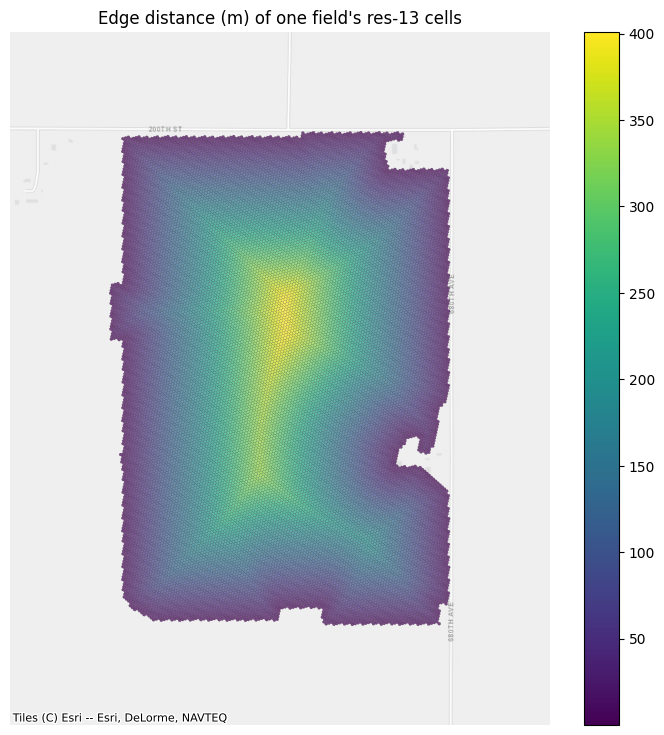

In [0]:
show_cells(spark.table("h3_field_cells").where("field_id = (SELECT field_id FROM field_polys ORDER BY area_m2 DESC LIMIT 1 OFFSET 100)"),
           "field_h3_cellid", "edge_dist_m", "Edge distance (m) of one field's res-13 cells")